# Sparse top-two expert routing

Send a point to two of four small expert networks. Their gate probabilities determine how the two responses combine.

A router assigns four logits to each point of a grid. Softmax over the two selected logits gives a convex combination. Fixed router and expert weights make it possible to check a sparse dispatch against an independent dense calculation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)


def sparse_layer(tokens, router, w1, w2):
    scores = tokens @ router.T
    selected = np.argsort(-scores, axis=1, kind="stable")[:, :2]
    gates = softmax(np.take_along_axis(scores, selected, axis=1))
    result = np.zeros(len(tokens))
    loads = np.zeros(len(router), dtype=int)
    for expert in range(len(router)):
        rows, slot = np.where(selected == expert)
        hidden = np.tanh(tokens[rows] @ w1[expert])
        result[rows] += gates[rows, slot] * (hidden @ w2[expert])
        loads[expert] = len(rows)
    return result, selected, gates, loads

## Dispatch the grid

The dense check evaluates every expert and gives excluded experts zero weight. Points on an exact tie use the lower expert index.

In [2]:
rng = np.random.default_rng(17)
coords = np.linspace(-1, 1, 46)
a, b = np.meshgrid(coords, coords)
tokens = np.column_stack((a.ravel(), b.ravel()))
router = np.array([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0], [0.0, -1.0]]) * 3
w1 = rng.normal(size=(4, 2, 8))
w2 = rng.normal(size=(4, 8))
out, ids, gates, loads = sparse_layer(tokens, router, w1, w2)
all_values = np.einsum("neh,eh->ne", np.tanh(np.einsum("nd,edh->neh", tokens, w1)), w2)
scores = tokens @ router.T
allow = np.zeros_like(scores, dtype=bool)
np.put_along_axis(allow, ids, True, axis=1)
dense = softmax(np.where(allow, scores, -np.inf))
assert np.allclose(out, (dense * all_values).sum(1))
assert loads.sum() == 2 * len(tokens) and np.allclose(gates.sum(1), 1)
report(
    ["Expert", "First choice", "Either choice", "Total gate weight"],
    [(i + 1, int((ids[:, 0] == i).sum()), loads[i], dense[:, i].sum()) for i in range(4)],
)
print(f"Expert evaluations for {len(tokens)} points: sparse {loads.sum()}, dense {4*len(tokens)}")

,Expert,First choice,Either choice,Total gate weight
0,1,552,1058,529.0
1,2,529,1058,529.0
2,3,529,1058,529.0
3,4,506,1058,529.0


Expert evaluations for 2116 points: sparse 4232, dense 8464


## Locate the routing boundaries

The map on the left shows the first expert. The map on the right includes both selected experts, so it can change smoothly inside one routing region.

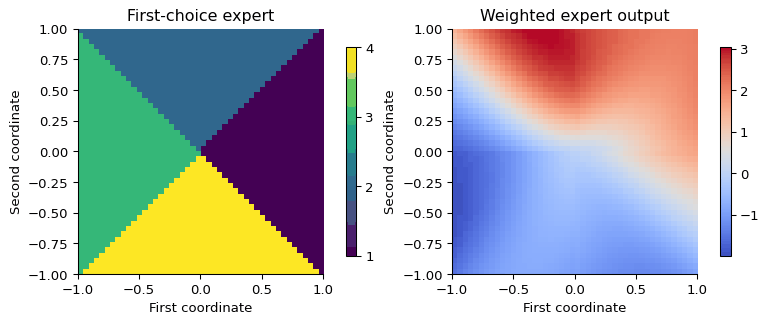

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3), layout="constrained")
for ax, val, title, cmap in zip(
    axes,
    [ids[:, 0] + 1, out],
    ["First-choice expert", "Weighted expert output"],
    ["viridis", "coolwarm"],
):
    im = ax.imshow(val.reshape(a.shape), origin="lower", extent=(-1, 1, -1, 1), cmap=cmap)
    ax.set(xlabel="First coordinate", ylabel="Second coordinate", title=title)
    fig.colorbar(
        im, ax=ax, shrink=0.85, ticks=[1, 2, 3, 4] if title.startswith("First") else None
    )
plt.show()

## Interpreting the result

Each point appears twice in the assignment count. Gate mass is different: its sum across experts equals the number of points. Both quantities matter when interpreting routing.

## Exercise

Add a constant to every router logit and check whether the selected experts or outputs change.

## References

[Shazeer et al. (2017), Outrageously Large Neural Networks](https://arxiv.org/abs/1701.06538)